## Day 6

### Use Case: Site Response and Wave Detection at a Strong-Motion Station

Japan operates one of the densest strong-motion networks in the world (K-NET, KiK-net) to characterize ground shaking during earthquakes. Two questions are central for every station:

1. **How does the local ground respond?** Soft soil above stiffer bedrock acts like a resonator: seismic waves are trapped in the layer and make it oscillate at its own *predominant period*. Buildings whose natural period lies close to this ground period experience resonance and are particularly vulnerable. Local site amplification has been discussed as a contributing factor to the severe damage in Mashiki during the 2016 Kumamoto earthquakes [source].
2. **When does a specific wave arrive?** Automatic monitoring systems must locate characteristic wave packets, such as the S-wave arrival, within a continuous record, for example for phase picking or for detecting aftershocks that resemble a known event (template matching).

This block investigates both questions using station KMM006 in Kumamoto Prefecture, located almost directly above the hypocenter of the M4.5 event on 2026-09-26.

### Problem Statement

**Autocorrelation (within the signal):** After the direct S wave, the record shows decaying oscillations (coda) that are expected to contain the resonance of the soil layer below the station. The goal is to identify the dominant recurring period in this part of the signal. Peaks in the autocorrelation at non-zero lag correspond to this period and allow an estimate of the predominant ground period at KMM006. The challenge is that an earthquake record is not truly periodic: it is a transient whose oscillations are only quasi-periodic and decay over time.

**Cross-correlation (segment detection):** A characteristic segment of the record, the high-amplitude S-wave packet, is used as a template. The goal is to locate this segment within the full window. The lag of maximum cross-correlation indicates its arrival time. The challenge is to obtain a distinct and reliable detection despite similar-looking oscillations elsewhere in the record, background noise, and amplitude variations.

| | Autocorrelation | Cross-correlation |
|---|---|---|
| Compares | the signal with shifted copies of itself | a template with the signal |
| Question | Does the signal repeat itself, and with which period? | Where does this pattern occur in the signal? |
| Result | dominant period [s] | position of the segment [s] |
| Domain meaning | soil resonance, relevant for building damage | wave arrival time, relevant for detection |

### Signal Selection

| Property | Value |
|---|---|
| Physical origin | Ground acceleration from the M4.5 earthquake on 2026-09-26, 10:31 (JST), Kumamoto, 10 km depth |
| Station / component | KMM006 (K-NET), NS (horizontal) |
| Unit | gal (= cm/s²) |
| Acquisition | Accelerometer, digitized at 100 Hz (raw counts × scale factor) |
| Window | 14–34 s (pre-event noise, P and S waves, coda) |
| Expected structures | Quasi-periodic oscillations in the coda (soil resonance); one distinct, high-amplitude S-wave packet |

**Choice of component.** The horizontal NS component is used because the S wave dominates horizontal motion, which makes the S-wave packet the most distinct segment in the record (peak ≈ −130 gal). Soil resonance also mainly affects horizontal shear motion, which is the motion most relevant for buildings.

**Choice of window.** The window contains every part needed for both analyses:
- *14–15 s, pre-event noise:* a region where the template should not match, which makes it possible to check whether a detection is specific.
- *≈ 16.5–18 s, S-wave packet:* the segment to be detected.
- *≈ 18–34 s, coda:* the decaying, quasi-periodic oscillations used for the autocorrelation.

The window ends at 34 s, where the signal has decayed close to the noise level.

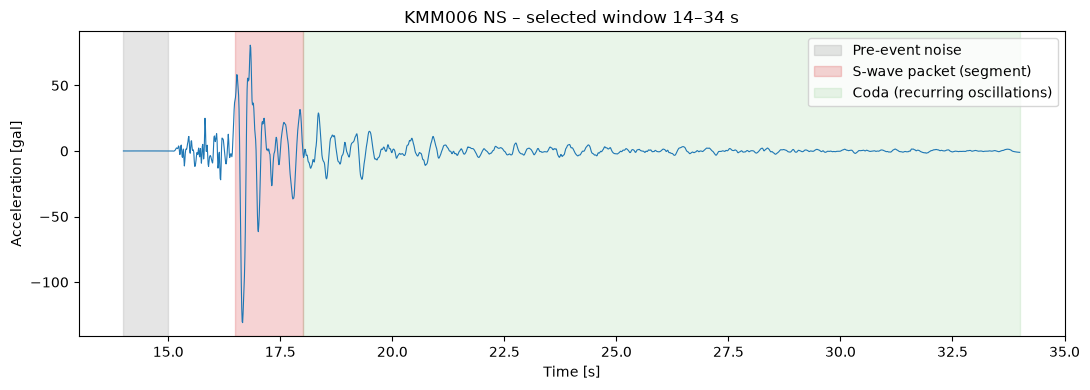

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from src.knet_io import read_knet

FILE = "data/20260926103100/knet/ascii/KMM0062609261031.NS"
T_START, T_END = 14.0, 34.0   # selected window [s]

acc, fs, hdr = read_knet(FILE)
t = np.arange(len(acc)) / fs
mask = (t >= T_START) & (t <= T_END)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t[mask], acc[mask], lw=0.8)
ax.axvspan(14, 15, color="gray", alpha=0.2, label="Pre-event noise")
ax.axvspan(16.5, 18, color="tab:red", alpha=0.2, label="S-wave packet (segment)")
ax.axvspan(18, 34, color="tab:green", alpha=0.1, label="Coda (recurring oscillations)")
ax.set(xlabel="Time [s]", ylabel="Acceleration [gal]",
       title=f"{hdr['Station Code']} NS – selected window {T_START:.0f}–{T_END:.0f} s")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### Why Recurring Structures Are Expected

Earthquake ground motion is a transient, not a periodic signal. Nevertheless, recurring structures are expected in the coda: after the direct S wave has passed, seismic energy keeps reflecting between the free surface and the stiffer bedrock below the station. The soil layer therefore "rings" at its natural frequency, which can be approximated by the quarter-wavelength rule $f_0 = v_S / (4H)$, where $v_S$ is the shear-wave velocity of the soil and $H$ the layer thickness. In the record, this appears as fairly regular oscillations after the S-wave packet, whose amplitude decays over time.

The S-wave packet, in contrast, is a single, distinct event with the highest amplitudes in the record. It occurs once and is therefore a suitable segment for detection.

### Why Correlation Is Appropriate

- **Autocorrelation** compares the signal with time-shifted copies of itself. If the signal repeats with period $T$, it is similar to itself at a lag of $T$, producing a peak in the autocorrelation. Because it uses the entire window rather than individual peaks, it is less sensitive to single irregular oscillations, which is important for a decaying, quasi-periodic signal.
- **Cross-correlation** slides the template along the signal and measures their similarity at each position. The position of maximum similarity marks where the segment occurs. This is the principle of the matched filter, a standard method for detecting known waveforms in noisy signals and the basis of template-matching earthquake detection.
- Both methods operate directly on the recorded time series and require no physical model of the source or the soil, which makes them suitable for routine, automatic analysis at many stations.

### Data Source

National Research Institute for Earth Science and Disaster Resilience (NIED): K-NET, KiK-net. doi:10.17598/NIED.0004

## Day 7

### Methodological Approach

| | Autocorrelation | Cross-correlation |
|---|---|---|
| Objective | Detect the global recurring pattern (dominant period) | Locate one specific segment within the record |
| Compares | the coda with shifted copies of itself | the S-wave template with every position of the window |
| Signal part | coda, ≈ 18–34 s | full window, 14–34 s |
| Result | lag of the first autocorrelation peak after zero lag = dominant period [s] | lag of the maximum = segment position [s] |

### Autocorrelation Remarks

The coda after the S wave consists of oscillations that are expected to repeat with the resonance period of the soil layer below the station. These oscillations are irregular in amplitude and decay over time, so single peaks in the time signal are unreliable for measuring their period. Autocorrelation instead compares the whole coda with the shifted copies of itself, so if the the signal repeats with period $T$, it is most likely to itself at lag $T$. This averages over time and makes itself robust against individual irregular oscillations.

**Parameters**

1. **Analysis Window: coda only (18-34s)** The S-wave packet occurs only once and has by far the highest amplitude. Including the S-wave would make the autocorrelation describe the shape of this single packet rather than the recurring ringing of the soil.
2. **Maximum Lag: 2s** Predominant ground periods typically lie between 0.1 and 1s. So using double of that therefore covers at least two cycles even for longer periods. At the same time it stays well below the window length of 16s.

**Normalization** The coda is mean-removed and the autocorrelation is divided by its value at zero lag. The result lies between -1 and 1 and expresses similarity independently of signal strength.

**Detection Criterion** The dominant period is the lag of the first local maximum after the zero lag.

### Crosscorrelation Remarks

The S-wave packet is a single, distinct waveform with the highest amplitudes and a characteristic shape. Cross correlation shifts this packet as a template along the record and measures the similarity at each position. The position of maximum similarity marks where the segment occurs.

**Parameters**

1. **Template: S-wave packet, 16.5-17.5s (1s, 100 samples)** It contains the strongest and distinctive part of the record. At dominant frequencies of about 2-4Hz, so 1 second covers about 2-4 oscillation cycles, enough to make the shape distinctive. Shorter templates could resemble coda and risk false matches, longer templates would include coda and lose specificity.
2. **Normalization: normalized Cross Correlation (NCC)** At each position, the template and th corresponding signal segment are mean-removed and divided by their standard deviations. The result lies again between -1 and 1 and compares only the shape, not the amplitude. Without normalization, high amplitude parts of the record would produce large values regardless of their similarity to the shape.

**Search Range** The template is compared at every position from the full window, including the pre-event noise, where no match should occur.

**Limitation** As the template is cut from the same signal, the NCC at the true position equals exactly 1, so the detection itself is trivial. The meaningful quantities are the distance between the main peak and next-highest peak, and the robustness of the detection under realistic perturbations.

#### Parameters

In [ ]:
from scipy.signal import find_peaks

FILE = "data/20260926103100/knet/ascii/KMM0062609261031.NS"
WINDOW = (14.0, 34.0)     # full analysis window [s]
CODA = (18.0, 34.0)       # autocorrelation part [s]
MAX_LAG = 2.0             # maximum autocorrelation lag [s]
TEMPLATE = (16.5, 17.5)   # S-wave segment for cross-correlation [s]

acc, fs, hdr = read_knet(FILE)


def cut(t0, t1):
    """Return the samples between t0 and t1 [s]."""
    return acc[int(round(t0 * fs)):int(round(t1 * fs))]

## Autocorrelation

In [6]:
def autocorr(x, max_lag):
    """Biased autocorrelation coefficient for lags 0..max_lag (in samples)."""
    x = x - x.mean()
    full = np.correlate(x, x, mode="full")         # raw sums, lags -(N-1)..(N-1)
    r = full[len(x) - 1:len(x) + max_lag]          # keep lags 0..max_lag
    return r / r[0]                                # normalize: r(0) = 1


coda = cut(*CODA)
r = autocorr(coda, int(MAX_LAG * fs))
lags = np.arange(len(r)) / fs

# Detection criterion (Day 7): first local maximum after the first zero crossing
first_neg = np.argmax(r < 0)
peaks, _ = find_peaks(r[first_neg:])
k_peak = first_neg + peaks[0]
T_acf = lags[k_peak]
print(f"Dominant period (autocorrelation): {T_acf:.3f} s  ->  {1 / T_acf:.2f} Hz")

Dominant period (autocorrelation): 0.310 s  ->  3.23 Hz


#### Reference value from the spectrum

In [8]:
spec = np.abs(np.fft.rfft(coda - coda.mean()))
freqs = np.fft.rfftfreq(len(coda), 1 / fs)
band = (freqs >= 0.5) & (freqs <= 20)          # ignore very slow drift and noise
f_ref = freqs[band][np.argmax(spec[band])]
T_ref = 1 / f_ref
print(f"Reference period (spectral peak): {T_ref:.3f} s  ->  {f_ref:.2f} Hz")

Reference period (spectral peak): 0.432 s  ->  2.31 Hz


#### Plot

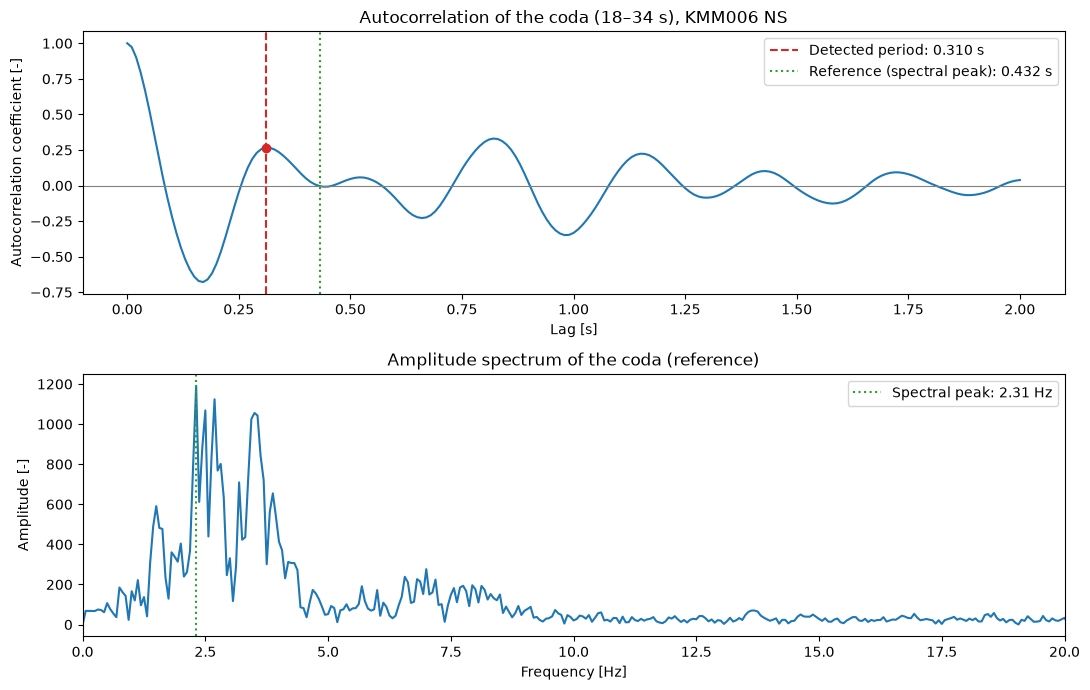

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))

ax1.plot(lags, r, color="tab:blue")
ax1.axhline(0, color="gray", lw=0.8)
ax1.axvline(T_acf, color="tab:red", ls="--", label=f"Detected period: {T_acf:.3f} s")
ax1.axvline(T_ref, color="tab:green", ls=":", label=f"Reference (spectral peak): {T_ref:.3f} s")
ax1.plot(T_acf, r[k_peak], "o", color="tab:red")
ax1.set(xlabel="Lag [s]", ylabel="Autocorrelation coefficient [-]",
        title=f"Autocorrelation of the coda ({CODA[0]:.0f}–{CODA[1]:.0f} s), KMM006 NS")
ax1.legend()

ax2.plot(freqs, spec, color="tab:blue")
ax2.axvline(f_ref, color="tab:green", ls=":", label=f"Spectral peak: {f_ref:.2f} Hz")
ax2.set(xlim=(0, 20), xlabel="Frequency [Hz]", ylabel="Amplitude [-]",
        title="Amplitude spectrum of the coda (reference)")
ax2.legend()

plt.tight_layout()
plt.show()

As noted, on the plot we have an oscillating curve that starts at 1 and decays. The decay is quasi-periodic behaviour plus the biased normalization. The red line at the first peak after the main lobe denotes the period of the spectrum and ideally the green curve is near it.

## Cross Correlation

In [10]:
def ncc(signal, template):
    """Normalized cross-correlation: Pearson correlation at every position."""
    n = len(template)
    t = (template - template.mean()) / template.std()
    out = np.empty(len(signal) - n + 1)
    for k in range(len(out)):
        seg = signal[k:k + n]
        std = seg.std()
        out[k] = 0.0 if std == 0 else np.sum((seg - seg.mean()) / std * t) / n
    return out


window = cut(*WINDOW)
template = cut(*TEMPLATE)
c = ncc(window, template)
t_pos = WINDOW[0] + np.arange(len(c)) / fs     # start time of each template position

k_best = np.argmax(c)
t_detected = t_pos[k_best]
t_true = TEMPLATE[0]
print(f"Detected position: {t_detected:.2f} s, true position: {t_true:.2f} s, "
      f"NCC max = {c[k_best]:.3f}")

Detected position: 16.50 s, true position: 16.50 s, NCC max = 1.000


#### Plot

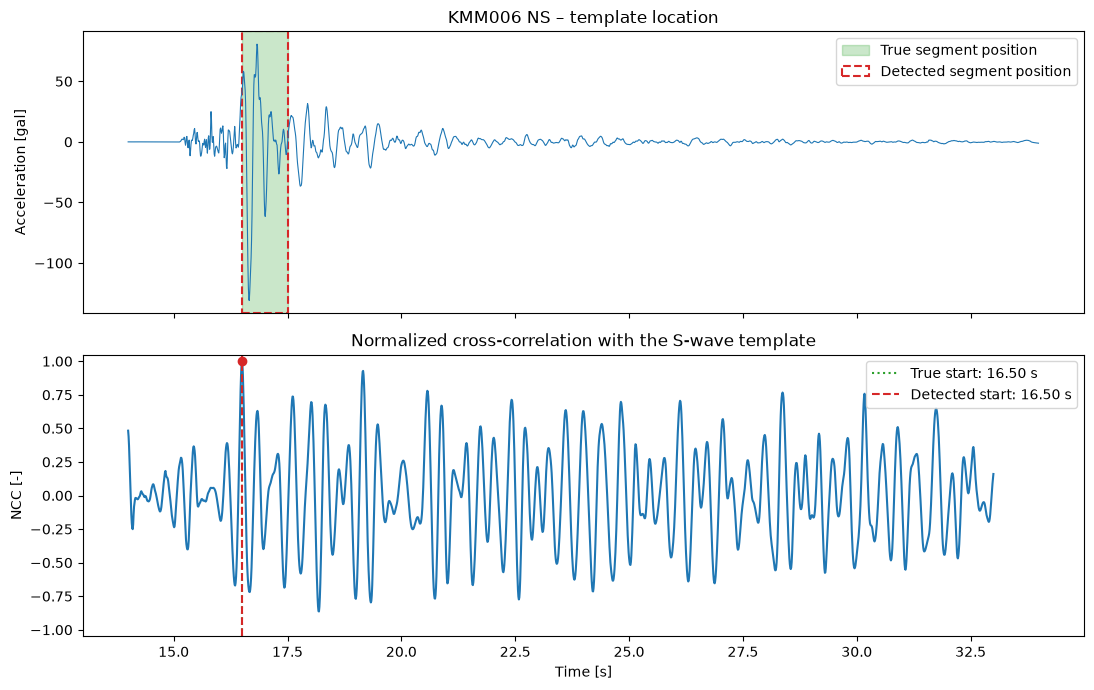

In [11]:
t_window = WINDOW[0] + np.arange(len(window)) / fs
dur = TEMPLATE[1] - TEMPLATE[0]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax1.plot(t_window, window, color="tab:blue", lw=0.8)
ax1.axvspan(t_true, t_true + dur, color="tab:green", alpha=0.25, label="True segment position")
ax1.axvspan(t_detected, t_detected + dur, fill=False, edgecolor="tab:red", ls="--", lw=1.5,
            label="Detected segment position")
ax1.set(ylabel="Acceleration [gal]", title="KMM006 NS – template location")
ax1.legend(loc="upper right")

ax2.plot(t_pos, c, color="tab:blue")
ax2.axvline(t_true, color="tab:green", ls=":", label=f"True start: {t_true:.2f} s")
ax2.axvline(t_detected, color="tab:red", ls="--", label=f"Detected start: {t_detected:.2f} s")
ax2.plot(t_detected, c[k_best], "o", color="tab:red")
ax2.set(xlabel="Time [s]", ylabel="NCC [-]", ylim=(-1.05, 1.05),
        title="Normalized cross-correlation with the S-wave template")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [12]:
peaks, _ = find_peaks(c)
outside = peaks[np.abs(t_pos[peaks] - t_detected) > (TEMPLATE[1] - TEMPLATE[0])]
k_second = outside[np.argmax(c[outside])]
print(f"Second-highest peak: NCC = {c[k_second]:.3f} at {t_pos[k_second]:.2f} s")

Second-highest peak: NCC = 0.928 at 19.16 s


The maximum (NCC=1) is located at 16.5 s, matching the true position. Several secondary peaks occur in the coda, where the oscillations look similar. The highest reching ~0.93 at ~19.2s, despite much lower signal amplitudes there.An NCC of exactly 1 at 16.5s, because the template matches itself. Values near 0 in the pre-event section (14-15s)

## Day 9 – Evaluation

### Evaluation Approach

**Autocorrelation – period accuracy.** The detected period $T_{ACF}$ is compared with an independent reference: the period of the strongest spectral peak of the coda, $T_{ref} = 1/f_{ref}$ (Day 8). The metric is the relative period error

$$e_T = \frac{|T_{ACF} - T_{ref}|}{T_{ref}} \cdot 100\,\%$$

It captures how accurately the recurring structure is identified. The spectral peak is a suitable reference because it estimates the same physical quantity, the dominant oscillation of the coda, with a different method (frequency domain instead of time domain). Its own uncertainty is limited by the spectral resolution $\Delta f = 1/L$, where $L$ is the window length; half a frequency bin corresponds to a period uncertainty of $\Delta T_{ref} \approx T_{ref}^2 / (2L)$.

**Cross-correlation – localization accuracy and distinctiveness.** The reference is the known cut position of the template ($t_{true}$ = 16.50 s). Two quantities are evaluated:
- **Lag error** $|t_{det} - t_{true}|$ in ms: whether the segment is found at the right place. A detection counts as correct if the lag error is at most 20 ms (2 samples).
- **Detection margin** $m = \text{NCC}(t_{true}) - \max(\text{NCC elsewhere})$, where "elsewhere" excludes positions within one template length of $t_{true}$. A positive margin means the true position wins; a negative margin means a false peak outranks it.

The margin is necessary because the unperturbed detection is trivially correct (NCC = 1 at the true position, Day 8). It quantifies how close competing peaks in the coda come to causing a false detection.

**Baseline configuration.** Coda window 18–34 s and max. lag 2 s (autocorrelation); template 16.5–17.5 s (1 s), NCC, no perturbation (cross-correlation).

#### Helper Functions

In [13]:
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view


def first_period(r):
    """Lag [s] and height of the first local maximum after the first zero crossing."""
    first_neg = np.argmax(r < 0)
    peaks, _ = find_peaks(r[first_neg:])
    if peaks.size == 0:
        return np.nan, np.nan
    k = first_neg + peaks[0]
    return k / fs, r[k]


def ncc_fast(signal, template):
    """Vectorized NCC, identical in result to ncc() from Day 8."""
    n = len(template)
    t = (template - template.mean()) / template.std()
    w = sliding_window_view(signal, n)
    sd = w.std(axis=1)
    num = (w - w.mean(axis=1, keepdims=True)) @ t / n
    return np.divide(num, sd, out=np.zeros_like(num), where=sd > 0)


def evaluate_detection(c, t_pos, t_true, dur):
    """Lag error [ms] of the maximum and detection margin [-] relative to the true position."""
    t_det = t_pos[np.argmax(c)]
    k_true = np.argmin(np.abs(t_pos - t_true))
    peaks, _ = find_peaks(c)
    elsewhere = peaks[np.abs(t_pos[peaks] - t_true) > dur]
    margin = c[k_true] - c[elsewhere].max()
    return t_det, 1000 * abs(t_det - t_true), margin


window = cut(*WINDOW)

# Check: the fast implementation matches the Day 8 loop
assert np.allclose(ncc_fast(window, cut(*TEMPLATE)), ncc(window, cut(*TEMPLATE)))

### Autocorrelation: Parameter Variation

The start of the coda window is varied (18, 20, 22, 24 s; end fixed at 34 s) to test how stable the period estimate is when earlier, stronger parts of the coda are excluded. The maximum lag (2 s) is kept fixed, as it only limits the visible lag range and does not affect the first peak as long as it exceeds the period. All configurations are compared with the same reference $T_{ref}$ from the baseline window.

In [14]:
CODA_STARTS = [18.0, 20.0, 22.0, 24.0]
L_ref = CODA[1] - CODA[0]
dT_ref = T_ref ** 2 / (2 * L_ref)
print(f"Reference: T_ref = {T_ref:.3f} s ± {dT_ref * 1000:.1f} ms (f_ref = {f_ref:.2f} Hz)")

rows = []
for t0 in CODA_STARTS:
    r_ = autocorr(cut(t0, CODA[1]), int(MAX_LAG * fs))
    T_, height = first_period(r_)
    rows.append({
        "Coda window [s]": f"{t0:.0f}–{CODA[1]:.0f}",
        "Baseline": t0 == CODA[0],
        "T_ACF [s]": round(T_, 3),
        "|T_ACF − T_ref| [ms]": round(1000 * abs(T_ - T_ref), 1),
        "e_T [%]": round(100 * abs(T_ - T_ref) / T_ref, 1),
        "Peak height [-]": round(height, 2),
    })

acf_results = pd.DataFrame(rows)
acf_results

Reference: T_ref = 0.432 s ± 5.8 ms (f_ref = 2.31 Hz)


,Coda window [s],Baseline,T_ACF [s],|T_ACF − T_ref| [ms],e_T [%],Peak height [-]
0,18–34,True,0.31,122.4,28.3,0.27
1,20–34,False,0.49,57.6,13.3,0.19
2,22–34,False,0.40,32.4,7.5,0.34
3,24–34,False,0.41,22.4,5.2,0.27


### Cross-Correlation: Parameter Variation

The template length is varied (0.25, 0.5, 1.0, 2.0 s), always starting at 16.5 s. Shorter templates contain fewer oscillation cycles and are expected to resemble coda oscillations more closely; longer templates include the transition from the S-wave packet into the coda.

In [15]:
TEMPLATE_LENGTHS = [0.25, 0.5, 1.0, 2.0]
T0 = TEMPLATE[0]
BASE_LENGTH = TEMPLATE[1] - TEMPLATE[0]


def run_detection(signal, length):
    c = ncc_fast(signal, cut(T0, T0 + length))
    t_pos = WINDOW[0] + np.arange(len(c)) / fs
    return evaluate_detection(c, t_pos, T0, length)


rows = []
for length in TEMPLATE_LENGTHS:
    t_det, err_ms, margin = run_detection(window, length)
    rows.append({
        "Template length [s]": length,
        "Baseline": length == BASE_LENGTH,
        "Detected start [s]": round(t_det, 2),
        "Lag error [ms]": round(err_ms, 1),
        "Detection margin [-]": round(margin, 3),
    })

xcf_clean = pd.DataFrame(rows)
xcf_clean

,Template length [s],Baseline,Detected start [s],Lag error [ms],Detection margin [-]
0,0.25,False,16.5,0.0,0.012
1,0.50,False,16.5,0.0,0.042
2,1.00,True,16.5,0.0,0.072
3,2.00,False,16.5,0.0,0.295


### Cross-Correlation: Robustness to Noise

**Perturbation.** Additive Gaussian white noise is added to the search window, while the template is kept clean. This corresponds to searching for a known waveform in a noisier recording, e.g. at a station with higher background noise or during a weaker event. The noise level is set by the signal-to-noise ratio

$$\text{SNR} = 10 \log_{10} \frac{P_{signal}}{P_{noise}} \quad [\text{dB}]$$

where $P_{signal}$ is the mean power of the baseline S-wave segment (16.5–17.5 s). The same $P_{signal}$ is used for all template lengths, so the noise level depends only on the SNR. Tested levels: 20, 10, 5, 0, −5 dB. Each level is repeated with 30 noise realizations (fixed random seed); the same realizations are used for all template lengths.

**Assumption.** Real seismic noise is not white: it is concentrated at certain frequencies (e.g. microseismic noise below 1 Hz). White noise is used as a simple, reproducible approximation.

**Reported per configuration:** detection rate (share of trials with lag error ≤ 20 ms), median lag error, and mean detection margin.

As the dB scale is logarithmic, the SNR levels correspond to the following noise amplitudes relative to the S-wave segment (noise σ / signal RMS = $10^{-\text{SNR}/20}$):

| SNR [dB] | 20 | 10 | 5 | 0 | −5 |
|---|---|---|---|---|---|
| Noise σ / signal RMS | 0.10 | 0.32 | 0.56 | 1.00 | 1.78 |

At 0 dB, the noise is thus as strong as the S-wave segment on average; at −5 dB, it is almost twice as strong. Absolute noise levels in gal are listed in the results table.

In [16]:
SNR_DB = [20, 10, 5, 0, -5]
N_TRIALS = 30
TOL_MS = 20

p_signal = np.mean(cut(*TEMPLATE) ** 2)
noise_bank = np.random.default_rng(42).standard_normal((N_TRIALS, len(window)))

rows = []
for length in TEMPLATE_LENGTHS:
    for snr in SNR_DB:
        sigma = np.sqrt(p_signal / 10 ** (snr / 10))
        res = np.array([run_detection(window + sigma * noise, length) for noise in noise_bank])
        rows.append({
            "Template length [s]": length,
            "SNR [dB]": snr,
            "Noise σ [gal]": round(sigma, 2),
            "Detection rate [%]": round(100 * np.mean(res[:, 1] <= TOL_MS), 1),
            "Median lag error [ms]": round(np.median(res[:, 1]), 1),
            "Mean detection margin [-]": round(np.mean(res[:, 2]), 3),
        })

xcf_noise = pd.DataFrame(rows)
xcf_noise

,Template length [s],SNR [dB],Noise σ [gal],Detection rate [%],Median lag error [ms],Mean detection margin [-]
0,0.25,20,4.76,100.0,0.0,0.047
1,0.25,10,15.04,100.0,0.0,0.084
2,0.25,5,26.75,100.0,0.0,0.127
3,0.25,0,47.56,100.0,10.0,0.138
4,0.25,-5,84.58,56.7,20.0,0.008
5,0.50,20,4.76,100.0,0.0,0.079
6,0.50,10,15.04,100.0,0.0,0.209
7,0.50,5,26.75,100.0,0.0,0.325
8,0.50,0,47.56,100.0,0.0,0.331
9,0.50,-5,84.58,93.3,10.0,0.157


#### Plot

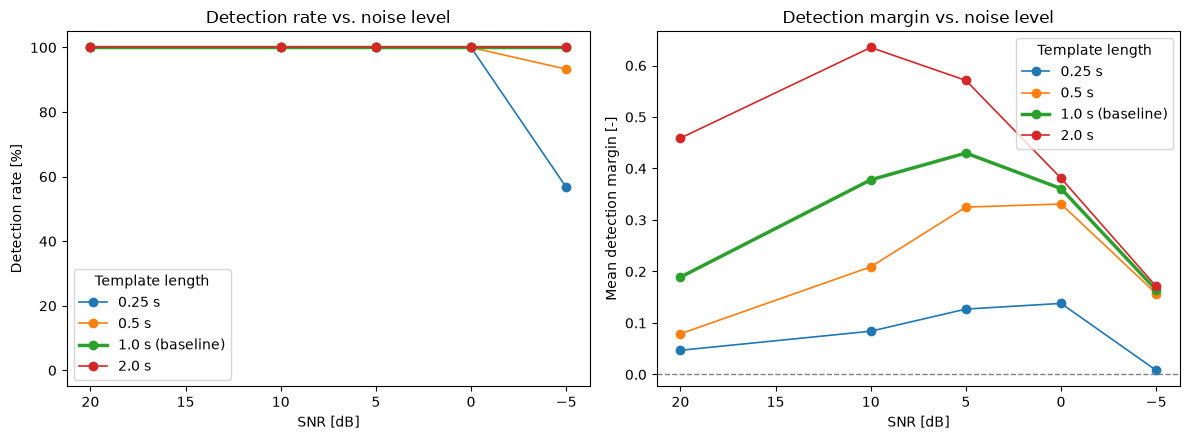

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

for length in TEMPLATE_LENGTHS:
    sub = xcf_noise[xcf_noise["Template length [s]"] == length]
    style = dict(lw=2.5) if length == BASE_LENGTH else dict(lw=1.2)
    label = f"{length} s" + (" (baseline)" if length == BASE_LENGTH else "")
    ax1.plot(sub["SNR [dB]"], sub["Detection rate [%]"], "o-", label=label, **style)
    ax2.plot(sub["SNR [dB]"], sub["Mean detection margin [-]"], "o-", label=label, **style)

ax1.set(xlabel="SNR [dB]", ylabel="Detection rate [%]", ylim=(-5, 105),
        title="Detection rate vs. noise level")
ax2.axhline(0, color="gray", ls="--", lw=1)
ax2.set(xlabel="SNR [dB]", ylabel="Mean detection margin [-]",
        title="Detection margin vs. noise level")
for ax in (ax1, ax2):
    ax.invert_xaxis()          # noise increases to the right
    ax.legend(title="Template length")
plt.tight_layout()
plt.show()

### Results

**Autocorrelation.** In the baseline window (18–34 s), the detected period is $T_{ACF}$ = 0.31 s, compared with $T_{ref}$ = 0.432 s ± 5.8 ms, i.e. $e_T$ = 28.3 %. When the window start is moved to 24 s, $e_T$ changes to 5.2 % and the peak height stays equal on 0.27.

**Cross-correlation without noise.** All template lengths locate the segment at 16.50 s (lag error 0 ms). The detection margin is 0.072 for the baseline (1 s), 0.012 for 0.25 s and 0.295 for 2 s.

**Cross-correlation under noise.** With the baseline template, the detection rate remains at 100 % down to an SNR of 0 dB and falls to 57 % at −5 dB for the 0.25s template and 93% for the 0.5s template, while the 1s and 2s template remain at 100%. The mean detection margin increases with template length at every noise level. For all template lengths, the margin first increases between 20dB until 5dB (10dB for 2.0 s) and then decreases towards -5dB, where it reaches almost 0 for the 0.25s template and ~0.17 for longer templates.


## Day 10 – Analysis & Communication

**Observations.** Autocorrelation of the planned coda window (18–34 s) yields 0.31 s, deviating 28 % from the spectral reference (0.432 s ± 6 ms). From a window start of 22 s, the estimate stabilizes at 0.40–0.41 s ($e_T$ ≤ 7.5 %), with low peak heights of 0.19–0.34. Cross-correlation locates the S-wave segment at 16.50 s in every noise-free case, but a coda peak at 19.16 s reaches NCC = 0.928 (margin 0.072). Under noise, templates of 1 s and longer detect the segment in all trials down to −5 dB, whereas the 0.25 s template falls to 57 %.

**Interpretation.** The early coda likely mixes S-wave remnants with site resonance; only the late coda reveals a stable but weak period of ≈ 0.41 s. This resonance also makes coda oscillations resemble the template, limiting the specificity of NCC. Longer templates include the transition into the coda and are therefore more distinctive. Moderate noise even increases the margin: at 20 dB (σ = 4.8 gal), noise already masks the weak coda while the S wave remains dominant.

**Discussion.** Detection is reliable for templates of at least 1 s down to −5 dB. Since white noise partly lies outside the signal band and only the search signal was perturbed, this robustness is likely optimistic; practical detectors should combine NCC with amplitude or multi-station criteria. The planned coda window started too early, showing that correlation parameters require inspection of the data. As the self-matched template made noise-free detection trivial, only the perturbations exposed the method's limits.